# Какую среднюю выбрать: правило из двух условий на ваших данных

[![Открыть в Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MarkNightingale/mean-estimator-choice/blob/main/notebooks/demo.ipynb)

Ноутбук показывает, как применить правило выбора оценки типичного уровня из исследования [mean-estimator-choice](https://github.com/MarkNightingale/mean-estimator-choice):

> Если за «усами» диаграммы размаха не больше 5 % наблюдений, а средняя отличается от медианы не больше чем на 0,20 MAD, используйте оценку Хьюбера. Иначе — медиану.

Порядок: данные о зарплате по регионам → правило → что будет при ошибке ввода → почему не всегда медиана → ваши данные. Все ячейки запускаются сверху вниз.

In [1]:
# В Colab пакет ставится из репозитория; локально ноутбук можно запустить из папки notebooks/
try:
    import estimator_choice
except ImportError:
    %pip install -q git+https://github.com/MarkNightingale/mean-estimator-choice
    import estimator_choice

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from estimator_choice import choose_estimator
from estimator_choice import estimators as est

print("версия пакета:", estimator_choice.__version__)

версия пакета: 1.1.0


## 1. Данные: зарплата в 85 субъектах РФ за 2025 г.

Среднемесячная номинальная начисленная заработная плата работников организаций, руб. (Росстат, через сервис StatBase). Десять регионов с самой высокой зарплатой:

In [2]:
URL = "https://raw.githubusercontent.com/MarkNightingale/mean-estimator-choice/main/data/wages_2025.csv"
try:
    wages = pd.read_csv("../data/wages_2025.csv")
except FileNotFoundError:
    wages = pd.read_csv(URL)

wages.sort_values("wage", ascending=False).head(10)

,region,wage
0,Чукотский автономный округ,214604
1,г. Москва,180861
2,Магаданская область,178076
3,Ямало-Ненецкий автономный округ,177711
4,Камчатский край,151016
5,Сахалинская область,148172
6,Ненецкий автономный округ,146957
7,Республика Саха (Якутия),139435
8,Ханты-Мансийский автономный округ – Югра,135914
9,Мурманская область,125302


## 2. Правило

Функция `choose_estimator` считает две характеристики выборки и по ним выбирает оценку. Заодно она возвращает среднюю, медиану и оценку Хьюбера, чтобы их можно было сравнить.

In [3]:
r = choose_estimator(wages["wage"])

print(f"Доля регионов за «усами»:   {r['share_outside']:.1%}  (порог 5 %)")
print(f"|средняя − медиана| / MAD:  {r['mean_median_gap']:.2f}   (порог 0,20)")
print()
names = {"mean": "средняя", "median": "медиана", "huber": "оценка Хьюбера"}
for k, v in r["estimates"].items():
    print(f"{names[k]:>15}: {v:9,.0f} руб.".replace(",", " "))
print()
print("Правило выбирает:", names[r["estimator"]])

Доля регионов за «усами»:   10.6%  (порог 5 %)
|средняя − медиана| / MAD:  0.68   (порог 0,20)

        средняя:    85 887 руб.
        медиана:    75 525 руб.
 оценка Хьюбера:    78 840 руб.

Правило выбирает: медиана


Оба условия нарушены: за «усами» больше 10 % регионов, и средняя заметно оторвалась от медианы. Типичный региональный уровень — медиана, 75,5 тыс. руб. Невзвешенная средняя выше на 14 %, потому что её тянут вверх северные регионы, Москва и Санкт-Петербург.

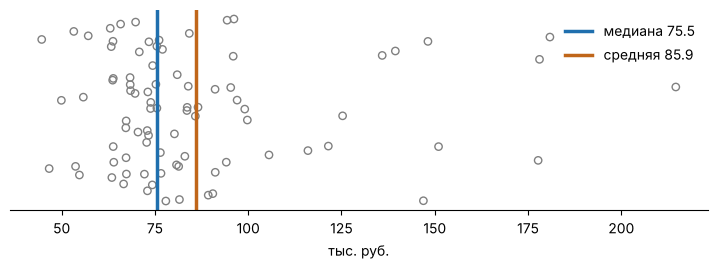

In [4]:
w = wages["wage"] / 1000
rng = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.scatter(w, rng.uniform(-0.3, 0.3, len(w)), s=28, facecolors="none", edgecolors="grey")
ax.axvline(w.median(), color="#1f6fae", lw=2.5, label=f"медиана {w.median():.1f}")
ax.axvline(w.mean(), color="#c0661a", lw=2.5, label=f"средняя {w.mean():.1f}")
ax.set_yticks([]); ax.set_xlabel("тыс. руб.")
ax.legend(frameon=False, loc="upper right")
for s in ("left", "right", "top"):
    ax.spines[s].set_visible(False)
plt.show()

## 3. Что будет при ошибке ввода

Допустим, в двух регионах значение ввели с лишним нулём. Посмотрим, насколько сдвинутся оценки.

In [5]:
rng = np.random.default_rng(11)
typo = wages["wage"].to_numpy(float).copy()
bad = rng.choice(len(typo), 2, replace=False)
typo[bad] *= 10
print("Ошибка в регионах:", ", ".join(wages["region"].iloc[bad]))

before, after = choose_estimator(wages["wage"]), choose_estimator(typo)
for k in ["mean", "huber", "median"]:
    change = round((after["estimates"][k] / before["estimates"][k] - 1) * 100, 1) + 0.0
    print(f"{names[k]:>15}: {change:+6.1f} %")

Ошибка в регионах: Московская область, г. Санкт-Петербург
        средняя:  +29.3 %
 оценка Хьюбера:   +0.0 %
        медиана:   +0.0 %


Средняя заметно выросла, а медиана и оценка Хьюбера почти не изменились. Сравнение средней с медианой — дешёвая проверка на такие ошибки.

## 4. Почему не всегда медиана

На «чистых» данных медиана заметно теряет точность. Небольшой эксперимент: 2 000 выборок по 50 наблюдений из нормального распределения без выбросов и с 10 % односторонних выбросов. В таблице — среднеквадратическая ошибка оценки (меньше — лучше).

In [6]:
rng = np.random.default_rng(1)

def mse(eps):
    x = est.draw_samples("normal", 50, eps, "one", 5, 2000, rng)
    E = est.all_estimates(x)
    F = est.features(x)
    rule = np.where((F[:, 5] <= 0.05) & (F[:, 6] <= 0.20), E[:, 3], E[:, 1])
    out = {est.EST_RU[name]: (E[:, j] ** 2).mean() for j, name in enumerate(est.EST_NAMES)}
    out["Правило из двух условий"] = (rule ** 2).mean()
    return pd.Series(out)

pd.DataFrame({"без выбросов": mse(0.0), "10 % выбросов": mse(0.10)}).round(4)

,без выбросов,10 % выбросов
Средняя,0.0193,0.3146
Медиана,0.0296,0.0569
Усечённая средняя (10 %),0.0200,0.1123
Оценка Хьюбера,0.0200,0.0759
Оценка Ходжеса – Лемана,0.0199,0.0834
Правило из двух условий,0.0232,0.0565


Без выбросов средняя и оценка Хьюбера точнее медианы примерно в полтора раза, с выбросами медиана намного лучше средней. Правило при выбросах не уступает медиане, а без них заметно точнее её.

## 5. Ваши данные

Подставьте свои значения в список или загрузите файл. В Colab загрузить CSV можно так: `from google.colab import files; files.upload()`, затем `pd.read_csv("имя_файла.csv")`.

In [7]:
values = [102, 98, 105, 110, 97, 101, 99, 104, 96, 1030]  # замените своими данными

r = choose_estimator(values)                 # осторожный вариант правила
print(names[r["estimator"]], "=", round(r["value"], 2))

r_soft = choose_estimator(values, variant="soft")  # мягкий вариант: 16 % и 0,30 MAD
print("мягкий вариант:", names[r_soft["estimator"]], "=", round(r_soft["value"], 2))

медиана = 101.5
мягкий вариант: медиана = 101.5
